In [ ]:
import torch

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.manifold import TSNE

from deepfake.data import frequency_ordered_nodes
from deepfake.constants import WAVELET_FAMILIES
from deepfake.features import get_node

In [2]:
node = frequency_ordered_nodes(level=3)[0]
wavelet = WAVELET_FAMILIES[0]
IDX = 5000

print("Loading datasets")
meta_2019 = pd.read_csv("./datasets/waveforms/eval_2019_meta.csv")
eval_2019 = np.load("./datasets/waveforms/eval_2019.npy")

meta_2019 = meta_2019[:IDX]
eval_2019 = eval_2019[:IDX]

Loading datasets


[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 5000 samples in 0.072s...
[t-SNE] Computed neighbors for 5000 samples in 21.435s...
[t-SNE] Computed conditional probabilities for sample 1000 / 5000
[t-SNE] Computed conditional probabilities for sample 2000 / 5000
[t-SNE] Computed conditional probabilities for sample 3000 / 5000
[t-SNE] Computed conditional probabilities for sample 4000 / 5000
[t-SNE] Computed conditional probabilities for sample 5000 / 5000
[t-SNE] Mean sigma: 7.030787
[t-SNE] KL divergence after 250 iterations with early exaggeration: 186.573090
[t-SNE] KL divergence after 1000 iterations: 4.353024


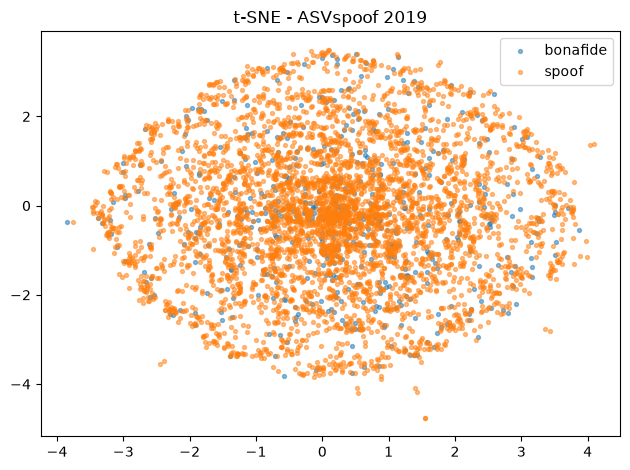

In [3]:
waveforms = torch.from_numpy(eval_2019.astype(np.float32) / 32768)

X_tsne = TSNE(
    n_components=2,
    max_iter=1000,
    learning_rate="auto",
    random_state=42,
    verbose=1
).fit_transform(waveforms)

y = meta_2019["is_bonafide"].astype(bool).values

plt.scatter(
    X_tsne[y, 0],
    X_tsne[y, 1],
    label="bonafide",
    alpha=0.5,
    s=8
)

plt.scatter(
    X_tsne[~y, 0],
    X_tsne[~y, 1],
    label="spoof",
    alpha=0.5,
    s=8
)

plt.title(f"t-SNE - ASVspoof 2019")
plt.legend()
plt.tight_layout()
plt.show()

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 5000 samples in 0.011s...
[t-SNE] Computed neighbors for 5000 samples in 2.484s...
[t-SNE] Computed conditional probabilities for sample 1000 / 5000
[t-SNE] Computed conditional probabilities for sample 2000 / 5000
[t-SNE] Computed conditional probabilities for sample 3000 / 5000
[t-SNE] Computed conditional probabilities for sample 4000 / 5000
[t-SNE] Computed conditional probabilities for sample 5000 / 5000
[t-SNE] Mean sigma: 5.623489
[t-SNE] KL divergence after 250 iterations with early exaggeration: 175.480560
[t-SNE] KL divergence after 950 iterations: 4.361749


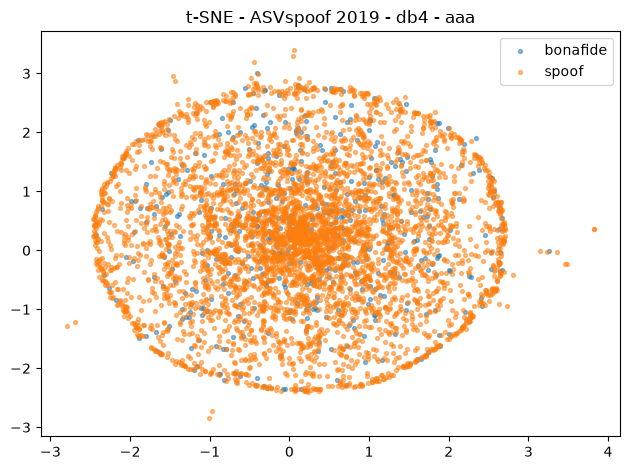

In [4]:
waveforms = torch.from_numpy(eval_2019.astype(np.float32) / 32768).unsqueeze(1)
data_transformed = get_node(waveforms, wavelet, 3, node).flatten(1).numpy()

X_tsne = TSNE(
    n_components=2,
    max_iter=1000,
    learning_rate="auto",
    random_state=42,
    verbose=1
).fit_transform(data_transformed)

y = meta_2019["is_bonafide"].astype(bool).values

plt.scatter(
    X_tsne[y, 0],
    X_tsne[y, 1],
    label="bonafide",
    alpha=0.5,
    s=8
)

plt.scatter(
    X_tsne[~y, 0],
    X_tsne[~y, 1],
    label="spoof",
    alpha=0.5,
    s=8
)

plt.title(f"t-SNE - ASVspoof 2019 - {wavelet} - {node}")
plt.legend()
plt.tight_layout()
plt.show()